# 03 Merge and embed: one map for mouse and human cells

1. **Match genes across species.** Mouse genes are renamed to their human equivalent, using
   only one-to-one pairs from MGI (one mouse gene ↔ one human gene). Genes without a clean
   partner are dropped.
2. **Merge** both datasets on the shared genes.
3. **Normalize → variable genes → PCA**, as in Leone Lab: `.X` is log-normalized to 1e4 over
   all genes, mito/ribo/hemoglobin genes are kept out of the variable-gene set, and PCA runs
   on a scaled copy of the variable genes only.
4. **Harmony** removes donor/species shifts so the same cell type from either species lands
   in the same place, then the **15-nearest-neighbour graph**, Leiden clusters, UMAP and PAGA.

Output: `processed/merged.h5ad` (log-normalized `.X`; raw counts stay in the 01/02 files).

In [1]:
import os, gc, re
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from config import *
from lcm import *

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
FIG = os.path.join("figures", "03_merge"); os.makedirs(FIG, exist_ok=True)

## 1. One-to-one mouse → human gene pairs (MGI)

In [2]:
hom = pd.read_csv(os.path.join(RAW, "orthologs", "HOM_MouseHumanSequence.rpt"), sep="\t", dtype=str)
hom = hom[["DB Class Key", "Common Organism Name", "Symbol"]].rename(columns={"DB Class Key": "key", "Common Organism Name": "org"})
hom["org"] = np.where(hom["org"].str.startswith("mouse"), "mouse", "human")
n = hom.groupby(["key", "org"]).size().unstack(fill_value=0)
one2one = n[(n["mouse"] == 1) & (n["human"] == 1)].index
h = hom[hom["key"].isin(one2one)].pivot(index="key", columns="org", values="Symbol")
# A human gene can sit in several MGI groups (e.g. AADACL4 pairs with 6 mouse paralogs, one per
# group), so also require each symbol to appear only once on both sides.
h = h[~h["human"].duplicated(keep=False) & ~h["mouse"].duplicated(keep=False)]
m2h = dict(zip(h["mouse"], h["human"]))
print(f"{len(m2h):,} one-to-one mouse-human gene pairs")

17,178 one-to-one mouse-human gene pairs


## 2. Load both QC'd datasets and keep shared genes

In [3]:
mouse = sc.read_h5ad(os.path.join(PROCESSED, "xiong_qc.h5ad"))
human = sc.read_h5ad(os.path.join(PROCESSED, "ramachandran_qc.h5ad"))
mouse = mouse[:, mouse.var_names.isin(list(m2h))].copy()
mouse.var_names = [m2h[g] for g in mouse.var_names]
shared = sorted(set(mouse.var_names) & set(human.var_names))
print(f"mouse genes with a 1:1 partner: {mouse.n_vars:,} | shared with human data: {len(shared):,}")
assert 10_000 < len(shared) < 18_000, "unexpected shared gene count; check the ortholog mapping"

keep_obs = ["dataset", "species", "sample", "donor", "condition", "celltype_native", "celltypist_conf",
            "n_genes_by_counts", "total_counts", "pct_counts_mt"]
parts = []
for a in (mouse, human):
    a = a[:, shared].copy()
    a.obs = a.obs[keep_obs]
    a.var = pd.DataFrame(index=a.var_names)
    parts.append(a)
del mouse, human; gc.collect()
adata = ad.concat(parts, join="inner")
del parts; gc.collect()
for c in ["dataset", "species", "sample", "donor", "condition", "celltype_native"]:
    adata.obs[c] = adata.obs[c].astype("category")
print(adata); ram("after merge")

mouse genes with a 1:1 partner: 13,776 | shared with human data: 13,171


AnnData object with n_obs × n_vars = 93077 × 13171
    obs: 'dataset', 'species', 'sample', 'donor', 'condition', 'celltype_native', 'celltypist_conf', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt'
[RAM] after merge process uses 1.8 GB


1.76717824

## 3. Harmonized cell types
The two CellTypist models use different label names, so both are mapped to one shared list.
Rules are checked in order; the table below shows every native label and where it went.

In [4]:
COARSE_RULES = [
    ("Hepatocyte", r"hepatocyte"),
    ("Cholangiocyte", r"cholangiocyte|biliary"),
    ("Endothelial", r"endothelial|lsec"),
    ("Stellate/Fibroblast", r"stellate|fibroblast|mesothelial|smooth muscle|myofibro|pericyte|vsmc"),
    # The mouse model says "Kupffer cells", the human model says "Macrophages" for the same
    # liver-resident macrophages, so they share one group.
    ("Kupffer/Macrophage", r"kupffer|macrophage"),
    ("Monocyte", r"monocyte|^mono"),
    ("Dendritic cell", r"dendritic|\bdc\b|cdc|pdc"),
    ("Granulocyte", r"neutrophil|granulocyte|basophil|mast"),
    ("B/Plasma cell", r"\bb cell|plasma|\bb\b"),
    ("T/NK cell", r"t cell|\bnk\b|nk cell|ilc|mait|gamma|cd4|cd8|treg|lymphoid"),
]
def coarse(label):
    l = str(label).lower()
    for name, pat in COARSE_RULES:
        if re.search(pat, l):
            return name
    return "Other"

mapping = pd.DataFrame({"native": adata.obs["celltype_native"].cat.categories})
mapping["cell_type"] = mapping["native"].map(coarse)
adata.obs["cell_type"] = adata.obs["celltype_native"].map(dict(zip(mapping["native"], mapping["cell_type"]))).astype("category")
mapping["n_cells"] = mapping["native"].map(adata.obs["celltype_native"].value_counts())
mapping.to_csv(os.path.join(FIG, "celltype_mapping.csv"), index=False)
print(mapping.sort_values(["cell_type", "native"]).to_string(index=False))

                            native           cell_type  n_cells
                           B cells       B/Plasma cell     5676
                      Plasma cells       B/Plasma cell      901
                    Cholangiocytes       Cholangiocyte     4268
                         Mig. cDCs      Dendritic cell      109
                             cDC1s      Dendritic cell      696
                             cDC2s      Dendritic cell     1946
                              pDCs      Dendritic cell      734
                 Endothelial cells         Endothelial    18476
                         Basophils         Granulocyte       53
                       Hepatocytes          Hepatocyte      727
                     Kupffer cells  Kupffer/Macrophage     3852
                       Macrophages  Kupffer/Macrophage     2930
           Mono+mono derived cells            Monocyte     6659
Monocytes & Monocyte-derived cells            Monocyte     3999
                       Fibroblasts Stell

In [5]:
pd.crosstab(adata.obs["cell_type"], adata.obs["species"])

species,human,mouse
cell_type,,
B/Plasma cell,2815,3762
Cholangiocyte,3531,737
Dendritic cell,1658,1827
Endothelial,8064,10412
Granulocyte,53,0
Hepatocyte,128,599
Kupffer/Macrophage,2930,3852
Monocyte,6659,3999
Stellate/Fibroblast,2326,366


## 4. Variable genes, normalize, PCA
Variable genes are picked on raw counts per sample (`seurat_v3`), so one sample's quirks can't
dominate. Then `.X` is log-normalized in place (no extra copy, to stay inside 8 GB RAM).

variable genes used for PCA: 2,991 (dropped 36 mt/ribo/hb)


/opt/anaconda3/envs/scrnaseq/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


[RAM] after PCA process uses 0.3 GB


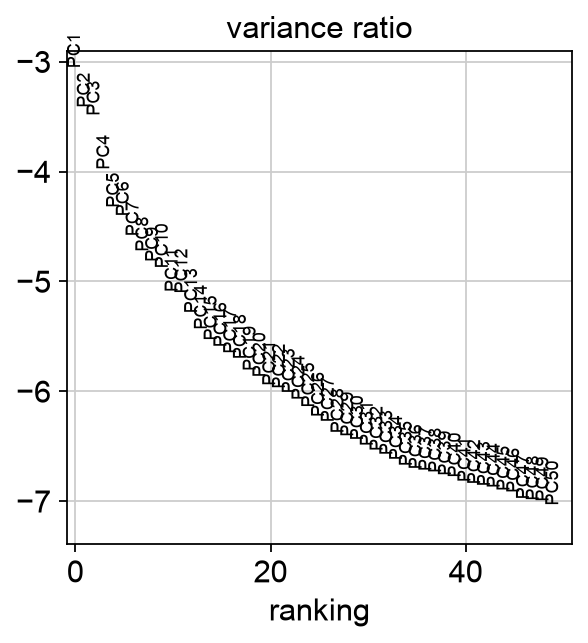

In [6]:
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3", batch_key="sample", span=0.5)
for key, pat in QC_PATTERNS["human"].items():
    adata.var[key] = adata.var_names.str.match(pat)
drop = adata.var["mt"] | adata.var["ribo"] | adata.var["hb"]
adata.var.loc[drop, "highly_variable"] = False
print(f"variable genes used for PCA: {int(adata.var['highly_variable'].sum()):,} (dropped {int((drop & adata.var['highly_variable_rank'].notna()).sum())} mt/ribo/hb)")

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
med = float(np.median(np.asarray(adata.X.expm1().sum(axis=1)).ravel()))
assert 9_000 < med < 11_000, med

hv = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(hv, max_value=10)
sc.tl.pca(hv, n_comps=N_PCS, svd_solver="arpack")
adata.obsm["X_pca"], adata.uns["pca"] = hv.obsm["X_pca"], hv.uns["pca"]
del hv; gc.collect(); ram("after PCA")
sc.pl.pca_variance_ratio(adata, n_pcs=N_PCS, log=True)

## 5. Harmony, graph, clusters, UMAP
Harmony corrects by **donor** (one mouse or one human). In the human data a donor's CD45+ and
CD45− runs differ in cell make-up on purpose, so correcting by run would push unlike cells
together; donor is the safer unit. Species sits above donor, so its shift is removed too.

In [7]:
import harmonypy
# Called directly: newer harmonypy returns Z_corr as cells x PCs, which scanpy's wrapper transposes wrongly.
ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, "donor", max_iter_harmony=20, verbose=False)
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, use_rep="X_pca_harmony")
sc.tl.leiden(adata, resolution=1.0, flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(adata)
sc.tl.paga(adata, groups="leiden")
ram("after graph")
print(adata.obs["leiden"].nunique(), "Leiden clusters")

/opt/anaconda3/envs/scrnaseq/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[RAM] after graph process uses 1.0 GB
31 Leiden clusters


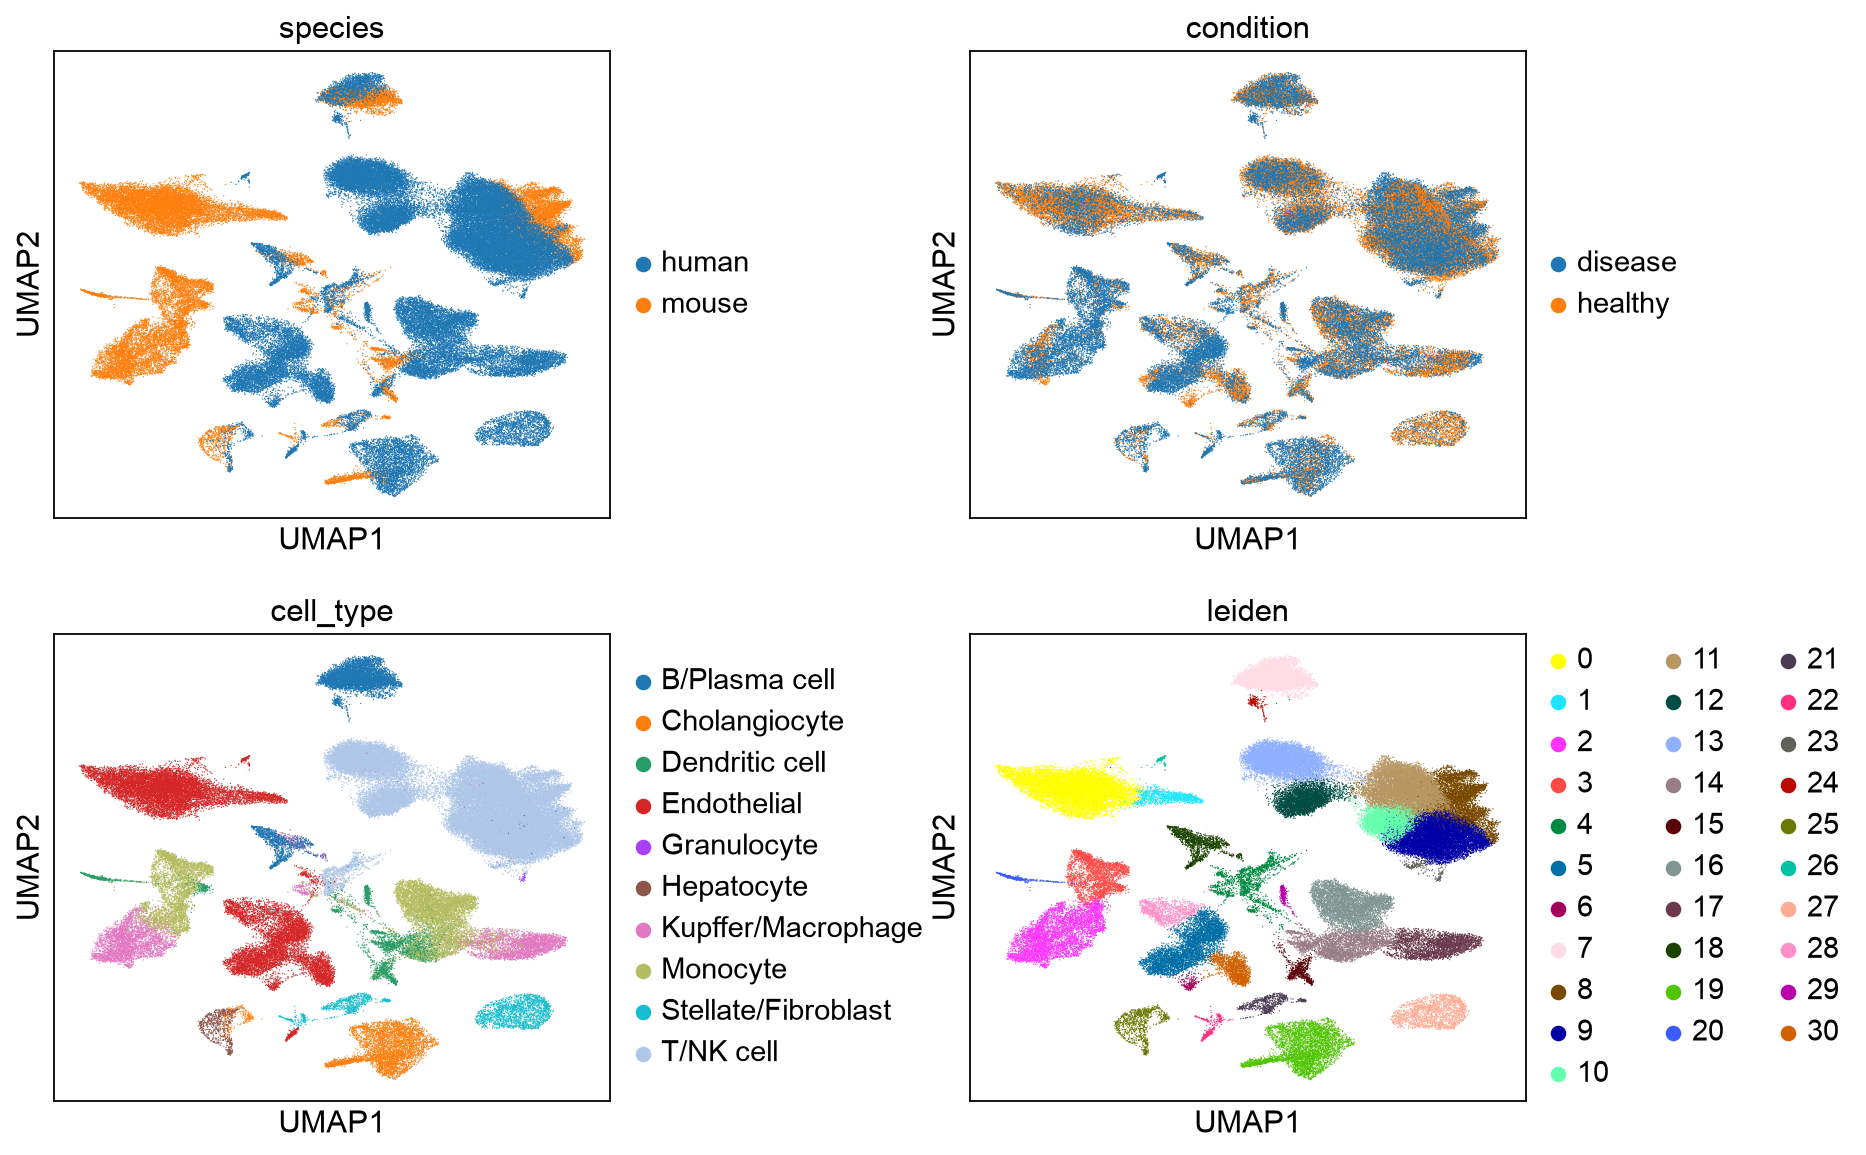

In [8]:
fig = sc.pl.umap(adata, color=["species", "condition", "cell_type", "leiden"], ncols=2, wspace=0.5, return_fig=True)
fig.savefig(os.path.join(FIG, "umap_overview.png"), bbox_inches="tight"); plt.show()

## 6. Save

In [9]:
safe_write(adata, os.path.join(PROCESSED, "merged.h5ad"))

wrote /Volumes/Crystal Hard Drive/CSE6242_data/processed/merged.h5ad | 93,077 cells x 13,171 genes | 0.34 GB
